# Real lutetium SPECT: photons to a three-dimensional activity volume


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：lutetium_spect_attenuation_resolution_activity

**观测 y：** energy_windows(1, 3, 96, 128, 128)；attenuation(1, 128, 128, 128)；angles(1, 96)；radii(1, 96)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 128³体素放射活度贡献。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** Poisson均值为旋转、衰减和深度PSF积分活度再加散射。本地路径为 `solvers.reconstruct(OSEM)`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 4, 6, 7, 11, 12, 13, 14, 16, 17, 19, 21（cell编号按文件内从0计）。章节包括：# Real lutetium SPECT: photons to a three-dimensional activity volume；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；### Removal of physical effects；### Actual stopping and subset sensitivity；### Approximate backprojection and limits of the physical claim；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** CT衰减是校准而非活度GT；Siemens历史重建也不是GT。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

A collimated gamma camera observes single photons from a real NEMA phantom. Recover all $128^3$ native activity voxels from 96 full detector views. CT attenuation and neighbouring energy windows are legitimate independent acquisition information. This notebook **actively reconstructs** the complete task using only the cleaned numerical implementation. No cached reconstruction substitutes for a fresh result.

The selected published example is Appendix A.2 / Figure A.6 of the PyTomography author manuscript. The author's modern source, its exact-input reproduction, the fresh cleaned run, and a historical Siemens reconstruction are distinct evidence. The nominal 10:1 filling ratio is not a voxelwise truth map. Native units are projection-count contribution per voxel, **not Bq/ml**.

## Current benchmark contract v2

Current acceptance uses nonnegative activity, all 96 photopeak views, the independently assembled attenuation/depth-PSF operator and fixed adjacent-window scatter. Original forward relative L2 <=0.22 remains. Normalized mean Poisson deviance <=0.1295695136004951 is the independently measured attainable 0.1295685136004951 plus predeclared 1e-6; it is not measured noise. An independent scalar likelihood improvement yields 0.12956534506424106 and forward L2 0.21913413980961838; zero and tenfold activity fail. Stable log differences avoid overflow at zero prediction. This certifies a measurement-consistent conditional reconstruction, with no unique spatial truth certification. The source reconstruction is unchanged. Earlier displayed agreement metrics are historical v1, not current acceptance boundaries.


In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,scatter_estimate,WINDOW_BOUNDS
from src.physics_model import Acquisition,DX,PSF_PARAMETERS,gaussian_kernel
from src.solvers import reconstruct
from src.visualization import image,metrics,projection_metrics,export_figure
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
torch.set_num_threads(1)
device='cuda' if torch.cuda.is_available() else 'cpu'
FIGDIR=Path(os.environ.get('IMAGING_FIGURE_DIR',str(ROOT/'output/figures')))
inventory=[]
def save(fig,stem,arrays,caption):
    image_axes=[a for a in fig.axes if a.images]
    for i,a in enumerate(image_axes):
        if stem=='fig01_measured_windows':labels=('Radial index','Axial index') if i<3 else ('View index','Radial index')
        elif stem in ['fig04_scatter_estimate','fig07_full_forward_residuals']:labels=('Radial index','Axial index')
        elif stem=='fig03_photon_and_collimator_physics':labels=('Detector-facing x index','Detector radial index')
        elif stem in ['fig02_independent_ct','fig05_fresh_volume_and_parity']:labels=[('x index','y index'),('x index','z index'),('y index','z index')][i%3]
        elif stem=='fig09_actual_physics_ablations':labels=('x index','y index') if i<4 else ('x index','z index')
        else:labels=('x index','y index')
        a.set_xlabel(labels[0]);a.set_ylabel(labels[1])
    inventory.append(export_figure(fig,FIGDIR,stem,arrays,caption));plt.show();plt.close(fig)
d=load_data(ROOT/'data/raw_data.npz')
g=d['energy_windows'][0].astype(np.float32)
scatter=scatter_estimate(d['energy_windows'],device)
up=np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz')
reference=up['reconstruction'][0]
vendor=np.load(ROOT/'notebooks/reference_outputs/historical_vendor.npz')['vendor_reconstruction']
print('Active device:',device,'threads:',torch.get_num_threads(),'torch:',torch.__version__)
print({k:(a.shape,str(a.dtype)) for k,a in d.items()})

Active device: cuda threads: 1 torch: 2.9.1+cu128
{'energy_windows': ((3, 96, 128, 128), 'uint16'), 'attenuation': ((128, 128, 128), 'float32'), 'angles': ((96,), 'float32'), 'radii': ((96,), 'float64')}


## 2. Data

All measured bins are retained. Storage order is window, angle, radial index, axial index after removing the batch axis. The three photon windows are independent measured channels; the CT array is already physically converted and registered by the author reader. Integer counts are losslessly retained. Angles are float32, radii float64, and CT attenuation float32 in cm$^{-1}$. The camera path is not approximated by a circular radius.

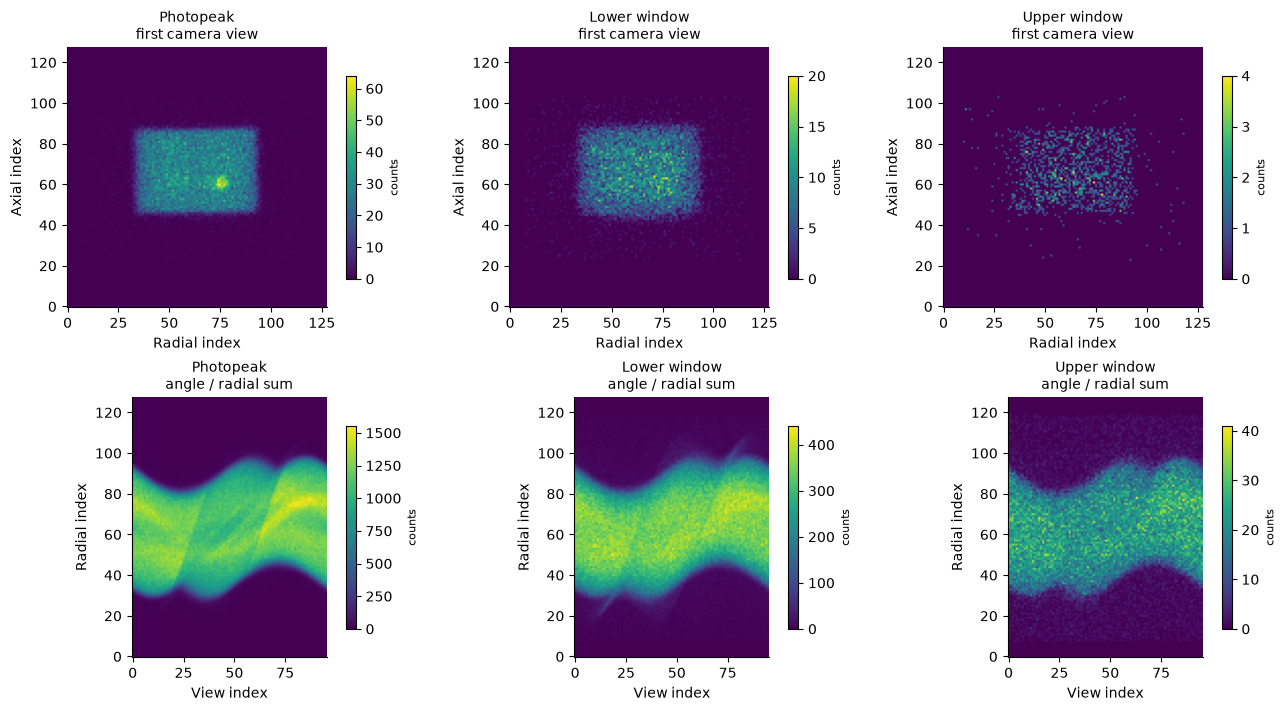

In [2]:
fig,ax=plt.subplots(2,3,figsize=(13,7))
for j,name in enumerate(['Photopeak','Lower window','Upper window']):
    image(ax[0,j],d['energy_windows'][j,0],name+'\nfirst camera view','counts')
    image(ax[1,j],d['energy_windows'][j].sum(axis=2),name+'\nangle / radial sum','counts')
save(fig,'fig01_measured_windows',{'windows':d['energy_windows'],'angles':d['angles']},'All three real count windows; lower panels integrate axial bins and retain angle/radial dimensions.')

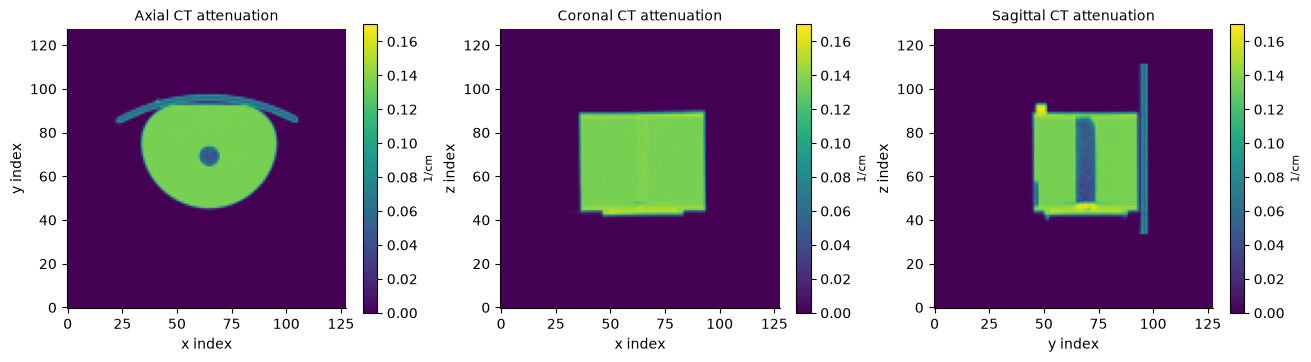

In [3]:
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
mu=d['attenuation']
for a,z,title in zip(ax,[mu[:,:,64],mu[:,64,:],mu[64,:,:]],['Axial CT attenuation','Coronal CT attenuation','Sagittal CT attenuation']): image(a,z,title,'1/cm',vmax=float(mu.max()))
save(fig,'fig02_independent_ct',{'attenuation':mu},'Independent CT calibration on the complete reconstruction lattice; no target-derived activity information.')

## 3. Physics

With activity $a$, photopeak counts $g$, survival probability $p$, scatter $s$, rotation $R$ and detector-parallel blur $K$,

$$g_{jrk}\sim\mathrm{Poisson}((Ha+s)_{jrk}),\qquad (Ha)_{jrk}=\sum_i[K_j(p_jR_ja)]_{irk}.$$

The voxel sum has no extra distance factor. The attenuation path includes half the emitting voxel:

$$p_{jirk}=\exp\left[-d\left(\tfrac12(R_j\mu)_{irk}+\sum_{h>i}(R_j\mu)_{hrk}\right)\right].$$

Here $d=0.47951998710631993$ cm. Rotations use 27-voxel zero padding, centred bilinear coordinates, and native float32 pi/normalisation. The detector is at increasing x after rotation. Gaussian standard deviation in centimetres at distance $D$ is $\sqrt{(A D+B)^2+C^2}$ with the exact calibrated coefficients in the README. Every depth kernel is discretely normalised.

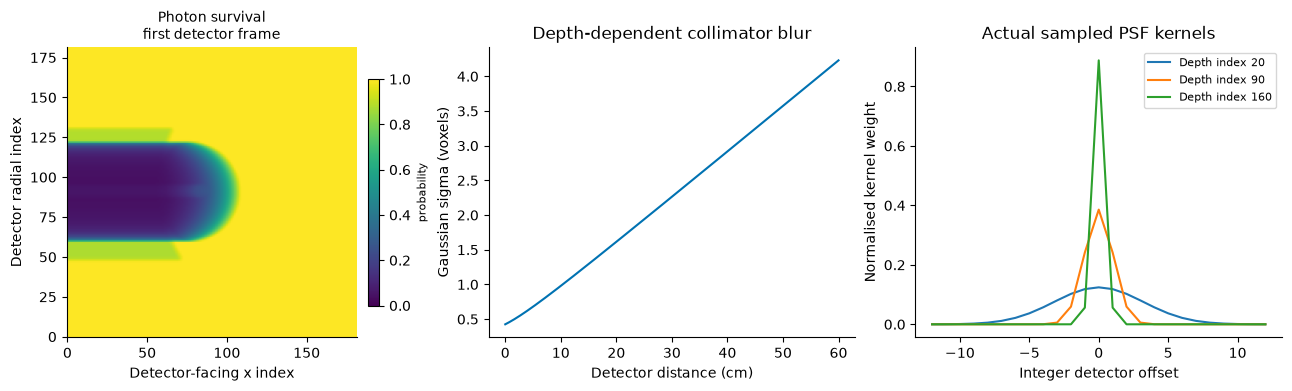

In [4]:
H=Acquisition(mu,d['angles'],d['radii'],device)
prob=H.probability(0).cpu().numpy()
distance=np.linspace(0,60,400)
a,b,c=PSF_PARAMETERS
sigma=np.sqrt((a*distance+b)**2+c*c)
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
image(ax[0],prob[:,:,64],'Photon survival\nfirst detector frame','probability',vmax=1)
ax[1].plot(distance,sigma/DX,color='#0072B2');ax[1].set(xlabel='Detector distance (cm)',ylabel='Gaussian sigma (voxels)',title='Depth-dependent collimator blur')
ker=gaussian_kernel(float(d['radii'][0]),182).cpu().numpy()[:,0]
offset=np.arange(-(ker.shape[1]//2),ker.shape[1]//2+1)
for depth in [20,90,160]:ax[2].plot(offset,ker[depth],label='Depth index '+str(depth))
ax[2].set(xlabel='Integer detector offset',ylabel='Normalised kernel weight',title='Actual sampled PSF kernels');ax[2].legend(fontsize=8)
save(fig,'fig03_photon_and_collimator_physics',{'probability':prob,'distance_cm':distance,'sigma_cm':sigma,'kernel':ker},'Actual first-view survival and Gaussian kernels; cm-to-voxel conversion retained.')

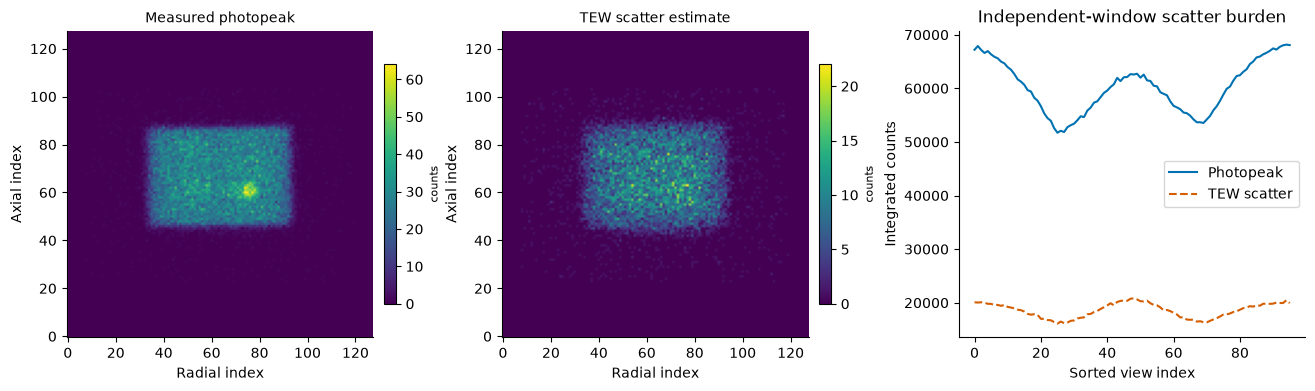

In [5]:
s=scatter.cpu().numpy()
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
image(ax[0],g[0],'Measured photopeak','counts')
image(ax[1],s[0],'TEW scatter estimate','counts')
ax[2].plot(g.sum((1,2)),label='Photopeak',color='#0072B2');ax[2].plot(s.sum((1,2)),label='TEW scatter',color='#D55E00',linestyle='--')
ax[2].set(xlabel='Sorted view index',ylabel='Integrated counts',title='Independent-window scatter burden');ax[2].legend()
save(fig,'fig04_scatter_estimate',{'photopeak_counts':g,'scatter_counts':s},'TEW remains additive; measured peak is not clipped or background-subtracted.')

## 4. Method

For each of eight interleaved angle subsets, let $B$ be the native inverse-angle continuous backprojector and $n=B\mathbf1$ its sensitivity. From $a=1$, the fixed 32 updates are

$$a\leftarrow\max\left(0,a+\left[a\frac1{n+\delta}\right]\left[B\left(\frac{g}{Ha+s+\delta}\right)-n\right]\right),\qquad\delta=10^{-11}.$$

The reciprocal multiplication and nonpositive-value projection retain source float32 conventions. No output-dependent mask, fitted intensity scaling, prior, early stopping or calibration update is introduced. **Inverse-angle interpolation is not the exact discrete transpose.** The separate refinement experiment later bounds this approximation. The four-iteration standard run below is active and fresh.

In [6]:
start=time.perf_counter()
q,states=reconstruct(H,g,scatter,capture=True)
if device=='cuda':torch.cuda.synchronize()
reconstruction_seconds=time.perf_counter()-start
fresh=q.cpu().numpy()
prediction=(H.forward(q)+scatter).cpu().numpy()
standard_metrics=metrics(fresh,reference)
standard_quality=projection_metrics(prediction,g)
print('Fresh complete reconstruction seconds:',reconstruction_seconds)
print('Agreement with independently reproduced original:',standard_metrics)
print('Full-data physical diagnostics:',standard_quality)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=fresh[None])
np.savez_compressed(ROOT/'notebooks/reference_outputs/cleaned_measurements.npz',reconstruction=fresh[None],prediction=prediction,updates=np.asarray(states))

Fresh complete reconstruction seconds: 1.2254066999885254
Agreement with independently reproduced original: {'ncc': 1.0000000000000002, 'nrmse': 0.0, 'max_error_over_reference_range': 0.0}
Full-data physical diagnostics: {'relative_L2': 0.2192173698222733, 'poisson_nll_without_factorial': -12340312.9301385}


## 5. Results

### Full-volume reconstruction and original-code agreement

Every displayed activity slice comes from the fresh complete reconstruction. The original-code result is a method reference, not hidden physical truth. Error panels are signed and centred at zero. Their colour limit remains finite when a run is bitwise identical.

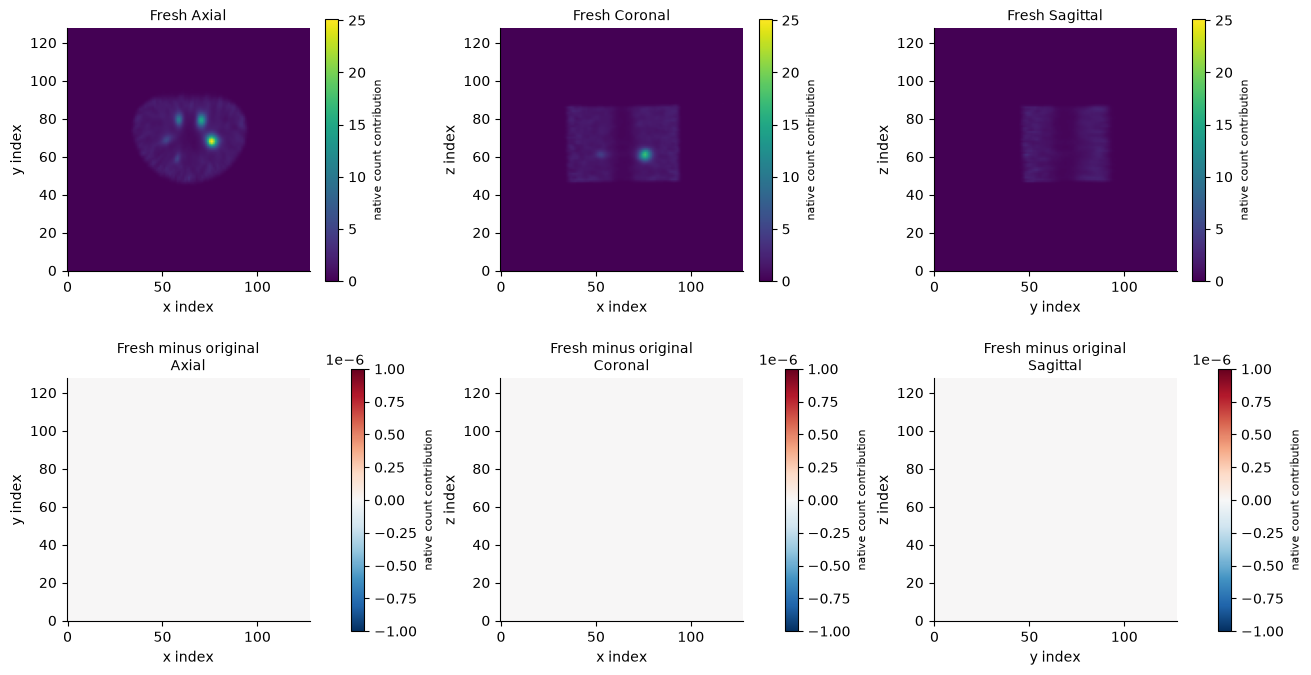

In [7]:
fig,ax=plt.subplots(2,3,figsize=(13,7))
vmax=float(reference.max());err=fresh-reference
for j,(a,r,e,name) in enumerate([(fresh[:,:,61],reference[:,:,61],err[:,:,61],'Axial'),(fresh[:,70,:],reference[:,70,:],err[:,70,:],'Coronal'),(fresh[64,:,:],reference[64,:,:],err[64,:,:],'Sagittal')]):
    image(ax[0,j],a,'Fresh '+name,'native count contribution',vmax=vmax)
    image(ax[1,j],e,'Fresh minus original\n'+name,'native count contribution',signed=True,vmax=max(float(abs(err).max()),1e-6))
save(fig,'fig05_fresh_volume_and_parity',{'fresh':fresh,'original':reference,'difference':err},'Full-FOV orthogonal slices z=61, y=70, x=64 (same author display convention) and independently reproduced original-code error; error does not represent physical truth.')

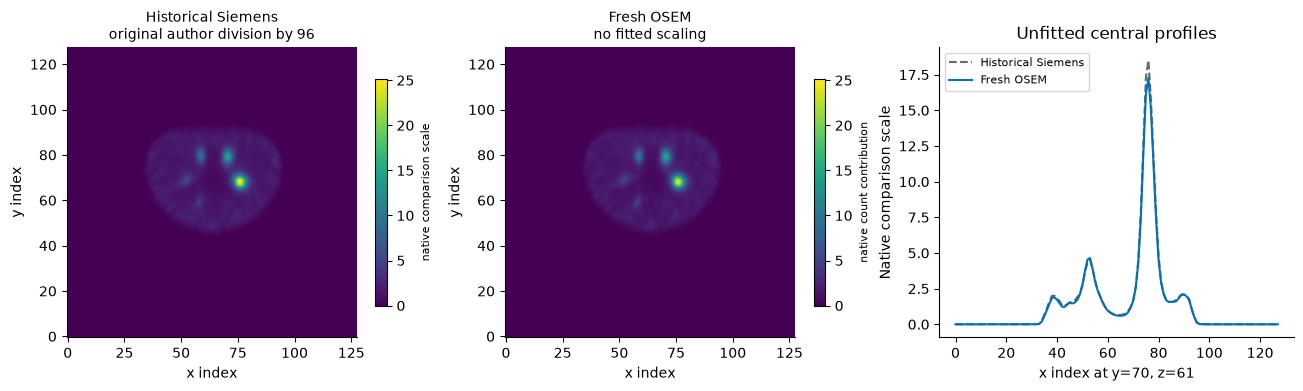

In [8]:
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
image(ax[0],vendor[:,:,61],'Historical Siemens\noriginal author division by 96','native comparison scale',vmax=vmax)
image(ax[1],fresh[:,:,61],'Fresh OSEM\nno fitted scaling','native count contribution',vmax=vmax)
ax[2].plot(vendor[:,70,61],label='Historical Siemens',color='#666666',linestyle='--');ax[2].plot(fresh[:,70,61],label='Fresh OSEM',color='#0072B2')
ax[2].set(xlabel='x index at y=70, z=61',ylabel='Native comparison scale',title='Unfitted central profiles');ax[2].legend(fontsize=8)
save(fig,'fig06_historical_vendor_comparison',{'historical_vendor':vendor,'fresh':fresh},'Author-supplied Siemens historical comparison, not freshly executed scanner reconstruction or voxelwise truth. No new fit of its scale.')

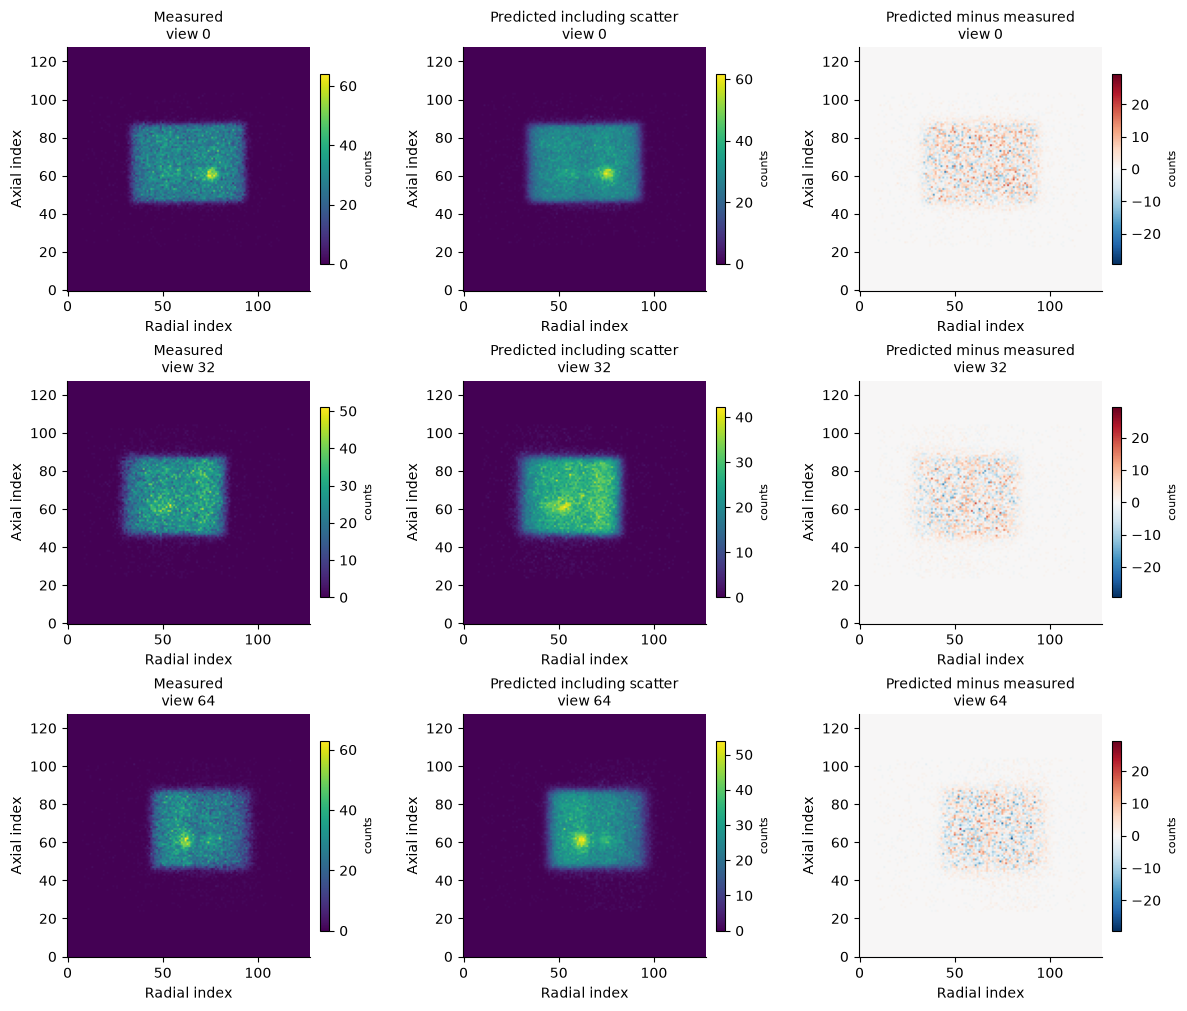

In [9]:
residual=prediction-g
fig,ax=plt.subplots(3,3,figsize=(12,10))
lim=float(abs(residual).max())
for row,j in enumerate([0,32,64]):
    image(ax[row,0],g[j],'Measured\nview '+str(j),'counts')
    image(ax[row,1],prediction[j],'Predicted including scatter\nview '+str(j),'counts')
    image(ax[row,2],residual[j],'Predicted minus measured\nview '+str(j),'counts',signed=True,vmax=lim)
save(fig,'fig07_full_forward_residuals',{'measured':g,'prediction':prediction,'signed_residual':residual},'Actual full forward residual at three fixed views; all detector bins enter the quantitative metric.')

NLL at initialization and iterations 1..4: [ 1.43174981e+08 -1.23050614e+07 -1.23321733e+07 -1.23378097e+07
 -1.23403129e+07]


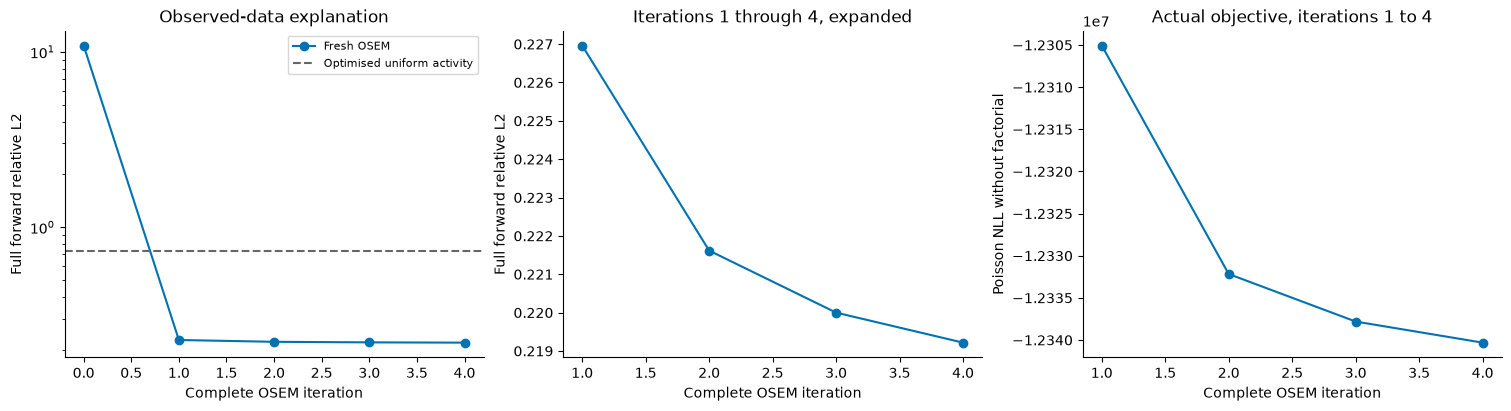

Optimised uniform null {'relative_L2': 0.7272667031012602, 'poisson_nll_without_factorial': -6520312.215779414} scatter-only null {'relative_L2': 0.7343370328035853, 'poisson_nll_without_factorial': -6742497.74050395}


In [10]:
iteration_images=[np.ones_like(fresh)]+[states[j] for j in [7,15,23,31]]
iteration_quality=[]
for a in iteration_images:
    p=(H.forward(torch.tensor(a,device=device))+scatter).cpu().numpy();iteration_quality.append(projection_metrics(p,g))
uniform_primary=H.forward(torch.ones(H.shape,device=device)).cpu().numpy()
scale=max(float((g.astype(float)-s).sum()/uniform_primary.astype(float).sum()),0.)
uniform_prediction=uniform_primary*scale+s
null_quality=projection_metrics(uniform_prediction,g)
fig,ax=plt.subplots(1,3,figsize=(15,4))
iters=np.arange(5);l2=np.array([v['relative_L2'] for v in iteration_quality]);nll=np.array([v['poisson_nll_without_factorial'] for v in iteration_quality])
ax[0].semilogy(iters,l2,'o-',color='#0072B2',label='Fresh OSEM');ax[0].axhline(null_quality['relative_L2'],color='#666666',linestyle='--',label='Optimised uniform activity')
ax[0].set(xlabel='Complete OSEM iteration',ylabel='Full forward relative L2',title='Observed-data explanation');ax[0].legend(fontsize=8)
ax[1].plot(iters[1:],l2[1:],'o-',color='#0072B2');ax[1].set(xlabel='Complete OSEM iteration',ylabel='Full forward relative L2',title='Iterations 1 through 4, expanded')
ax[2].plot(iters[1:],nll[1:],'o-',color='#0072B2');ax[2].set(xlabel='Complete OSEM iteration',ylabel='Poisson NLL without factorial',title='Actual objective, iterations 1 to 4')
print('NLL at initialization and iterations 1..4:',nll)
save(fig,'fig08_convergence_and_null',{'iterations':iters,'relative_l2':l2,'poisson_nll':nll,'uniform_relative_l2':np.array(null_quality['relative_L2'])},'Actual states and full-data objective (initial NLL retained in paired numeric source and printed table); fixed four-iteration stop, no inference of convergence to a global optimum.')
print('Optimised uniform null',null_quality,'scatter-only null',projection_metrics(s,g))

### Removal of physical effects

Each comparison below is actually reconstructed from the same complete observations. Removing attenuation, resolution modelling or scatter changes the acquisition assumption and is explicitly labelled. We evaluate every resulting volume using the **same complete calibrated physical forward model**, so a weaker model cannot win by changing its scoring equation.

{'Complete': {'relative_L2': 0.2192173698222733, 'poisson_nll_without_factorial': -12340312.9301385}, 'No attenuation': {'relative_L2': 0.5217084645594788, 'poisson_nll_without_factorial': -11281900.749176303}, 'No PSF': {'relative_L2': 0.22079700948078063, 'poisson_nll_without_factorial': -12326266.598618574}, 'No TEW': {'relative_L2': 0.36079529208512534, 'poisson_nll_without_factorial': -12137234.60131333}}


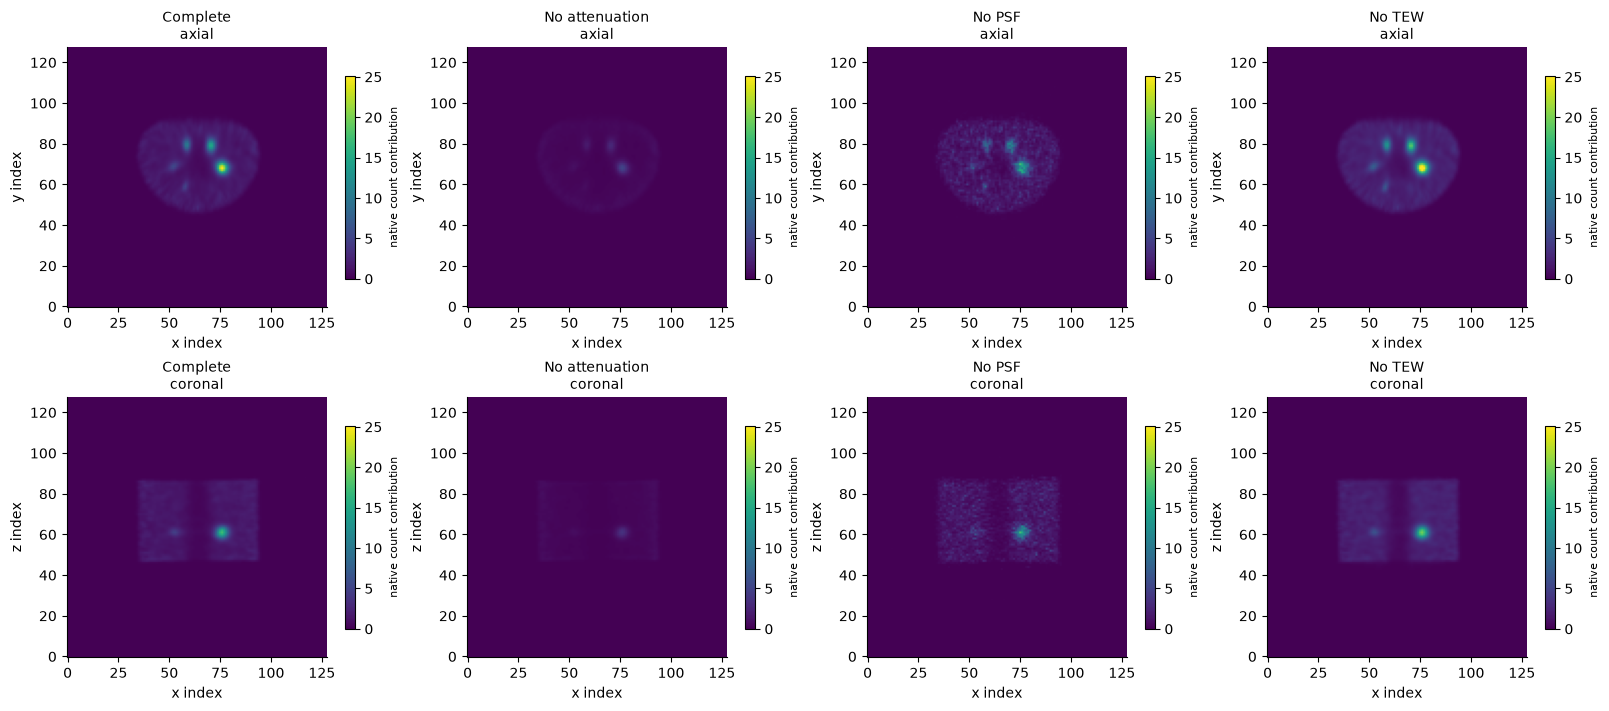

In [11]:
ablations={'Complete':fresh};ablation_quality={'Complete':standard_quality}
for name,ae,pe,tew in [('No attenuation',False,True,True),('No PSF',True,False,True),('No TEW',True,True,False)]:
    model=Acquisition(mu,d['angles'],d['radii'],device,attenuation_enabled=ae,psf_enabled=pe)
    a,_=reconstruct(model,g,scatter if tew else torch.zeros_like(scatter))
    ablations[name]=a.cpu().numpy();physical_prediction=(H.forward(a)+scatter).cpu().numpy();ablation_quality[name]=projection_metrics(physical_prediction,g)
    del model,a
print(ablation_quality)
fig,ax=plt.subplots(2,4,figsize=(16,7))
for j,(name,a) in enumerate(ablations.items()):
    image(ax[0,j],a[:,:,61],name+'\naxial','native count contribution',vmax=vmax)
    image(ax[1,j],a[:,70,:],name+'\ncoronal','native count contribution',vmax=vmax)
save(fig,'fig09_actual_physics_ablations',{'activity_'+str(j):a for j,a in enumerate(ablations.values())},'Four fresh full-volume inversions. Shared display scale makes amplitude bias visible; no per-panel intensity fitting.')

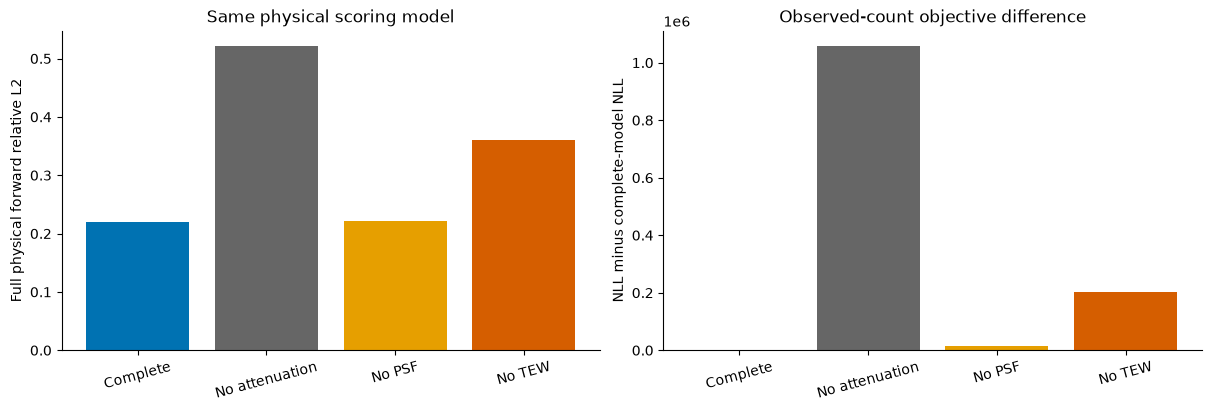

In [12]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
labels=list(ablations);values=np.array([ablation_quality[k]['relative_L2'] for k in labels]);objective=np.array([ablation_quality[k]['poisson_nll_without_factorial'] for k in labels])
ax[0].bar(np.arange(4),values,color=['#0072B2','#666666','#E69F00','#D55E00']);ax[0].set_xticks(np.arange(4),labels,rotation=15);ax[0].set(ylabel='Full physical forward relative L2',title='Same physical scoring model')
ax[1].bar(np.arange(4),objective-objective[0],color=['#0072B2','#666666','#E69F00','#D55E00']);ax[1].set_xticks(np.arange(4),labels,rotation=15);ax[1].set(ylabel='NLL minus complete-model NLL',title='Observed-count objective difference')
save(fig,'fig10_ablation_metrics',{'relative_l2':values,'nll':objective},'Ablation metrics use identical measured data and the complete physical model; positive NLL difference is worse.')

### Actual stopping and subset sensitivity

Additional iterations and a one-subset comparison are fresh diagnostic experiments, not replacements for the bound four-iteration/eight-subset output. They expose dependence on finite update count and prevent standard-method agreement from being mistaken for unique physical truth.

Eight iterations physical quality: {'relative_L2': 0.21776519155651328, 'poisson_nll_without_factorial': -12344068.983195174}


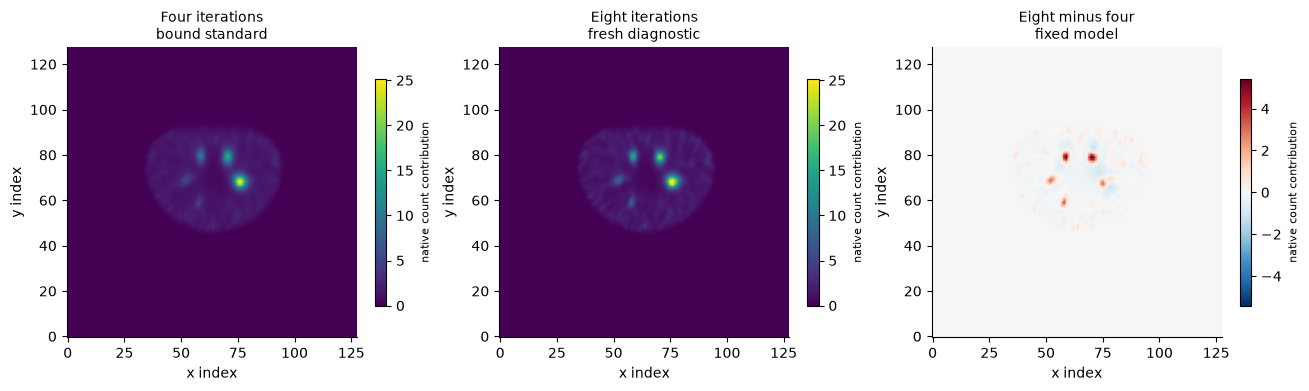

One subset/four iterations physical quality: {'relative_L2': 0.2713295919447986, 'poisson_nll_without_factorial': -12063510.42531371}


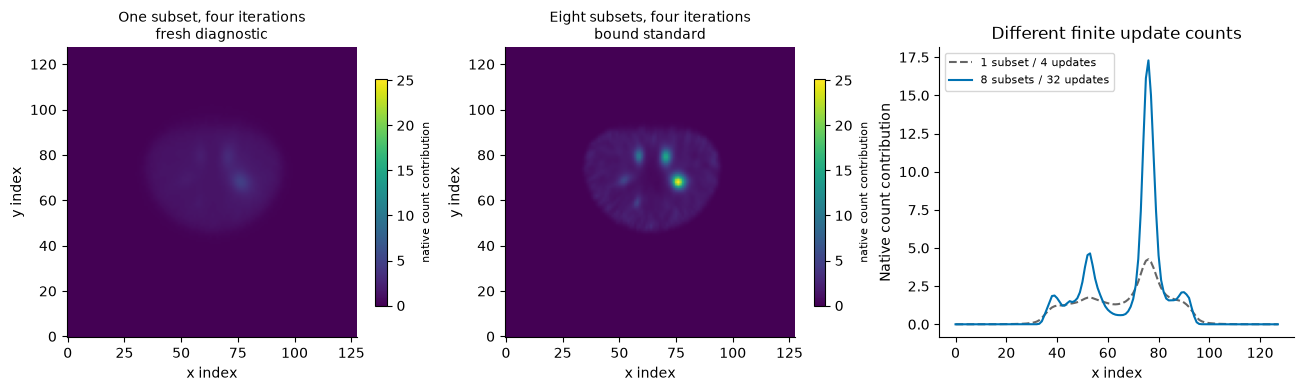

In [13]:
q8,states8=reconstruct(H,g,scatter,n_iterations=8,capture=True)
a8=q8.cpu().numpy();p8=(H.forward(q8)+scatter).cpu().numpy()
print('Eight iterations physical quality:',projection_metrics(p8,g))
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
image(ax[0],fresh[:,:,61],'Four iterations\nbound standard','native count contribution',vmax=vmax)
image(ax[1],a8[:,:,61],'Eight iterations\nfresh diagnostic','native count contribution',vmax=vmax)
image(ax[2],(a8-fresh)[:,:,61],'Eight minus four\nfixed model','native count contribution',signed=True)
save(fig,'fig11_actual_iteration_sensitivity',{'four_iterations':fresh,'eight_iterations':a8,'forward8':p8},'Actual extra iterations show finite-iteration dependence; no replacement of the selected standard.')
H1=Acquisition(mu,d['angles'],d['radii'],device,n_subsets=1)
q1,_=reconstruct(H1,g,scatter,n_iterations=4);a1=q1.cpu().numpy();p1=(H.forward(q1)+scatter).cpu().numpy()
print('One subset/four iterations physical quality:',projection_metrics(p1,g))
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
image(ax[0],a1[:,:,61],'One subset, four iterations\nfresh diagnostic','native count contribution',vmax=vmax)
image(ax[1],fresh[:,:,61],'Eight subsets, four iterations\nbound standard','native count contribution',vmax=vmax)
ax[2].plot(a1[:,70,61],label='1 subset / 4 updates',linestyle='--',color='#666666');ax[2].plot(fresh[:,70,61],label='8 subsets / 32 updates',color='#0072B2');ax[2].set(xlabel='x index',ylabel='Native count contribution',title='Different finite update counts');ax[2].legend(fontsize=8)
save(fig,'fig12_actual_subset_sensitivity',{'one_subset_activity':a1,'eight_subset_activity':fresh,'one_subset_prediction':p1},'Fresh one-subset comparison; four iterations have four updates rather than 32, so this is finite-update sensitivity, not matched-convergence ranking.')
del H1,q1,q8,states8

### Approximate backprojection and limits of the physical claim

The original implementation uses inverse-angle bilinear sampling for the continuous backprojector. It is not the exact transpose of discrete interpolation. The independent fixed-FOV refinement fixture below was produced before local extraction by explicitly constructing bilinear matrices and their exact transposes. Smooth-probe integrated dot products approach agreement, but pointwise inverse-rotation versus discrete-transpose differences remain about 7%. These are different diagnostics; neither is hidden or relabelled as exact adjointness.

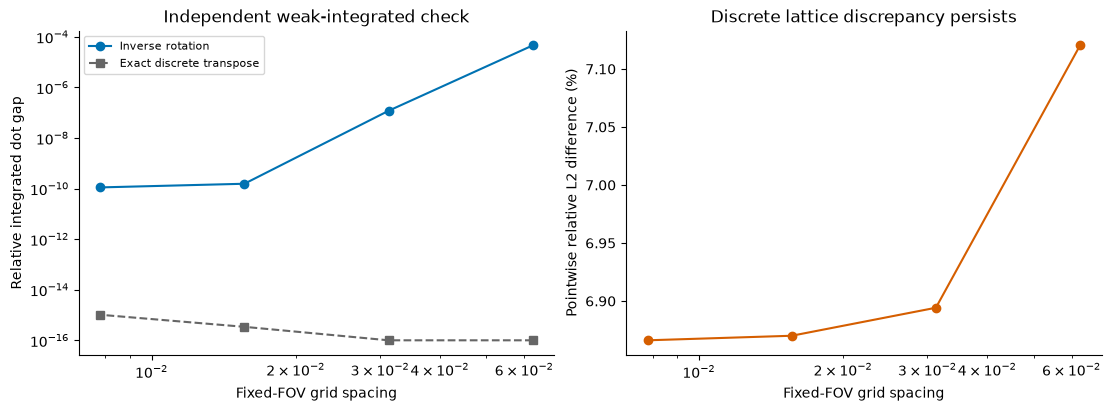

In [14]:
r=np.load(ROOT/'test/fixtures/independent_adjoint_refinement.npz')
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].loglog(r['grid_spacing'],r['inverse_rotation_dot_relative_gap'],'o-',color='#0072B2',label='Inverse rotation');ax[0].loglog(r['grid_spacing'],np.maximum(r['exact_transpose_dot_relative_error'],1e-16),'s--',color='#666666',label='Exact discrete transpose')
ax[0].set(xlabel='Fixed-FOV grid spacing',ylabel='Relative integrated dot gap',title='Independent weak-integrated check');ax[0].legend(fontsize=8)
ax[1].semilogx(r['grid_spacing'],100*r['inverse_vs_transpose_on_smooth_probe_relative_L2'],'o-',color='#D55E00');ax[1].set(xlabel='Fixed-FOV grid spacing',ylabel='Pointwise relative L2 difference (%)',title='Discrete lattice discrepancy persists')
save(fig,'fig13_independent_adjoint_limitation',{k:r[k] for k in r.files},'Independent pre-extraction physics fixture: weak-integrated agreement does not imply exact discrete-transpose or pointwise convergence.')

## 6. Conclusion

The full real observations were actively reconstructed and compared against an independent author-code run. CT attenuation, distance-dependent blur and additive TEW scatter all enter explicit local mathematics. The benchmark measures agreement with a fixed published estimator; it does not invent voxelwise activity truth or an absolute concentration calibration.

Physical residuals, actual nulls, removal-of-physics inversions and iteration/subset sensitivity bound the claim. Finite iteration, estimated scatter, Gaussian collimator response and approximate continuous backprojection remain material limitations. The historical vendor reconstruction is useful context but is neither fresh nor ground truth.

In [15]:
summary={'device':device,'threads':torch.get_num_threads(),'active_reconstruction_seconds':reconstruction_seconds,'agreement':standard_metrics,'full_physical_quality':standard_quality,'null_quality':null_quality,'ablation_quality':ablation_quality,'figure_count':len(inventory)}
(FIGDIR/'experiment_summary.json').write_text(json.dumps(summary,indent=2,allow_nan=False))
(FIGDIR/'figure_inventory.json').write_text(json.dumps(inventory,indent=2,allow_nan=False))
assert standard_metrics['nrmse']<=1e-6 and standard_quality['relative_L2']<=.22
print(json.dumps(summary,indent=2))
import subprocess
judge_run=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert judge_run.returncode==0,(judge_run.stdout,judge_run.stderr)
print('Independent standalone Judge:',(ROOT/'output/judge_report.json').read_text(encoding='utf8'))

{
  "device": "cuda",
  "threads": 1,
  "active_reconstruction_seconds": 1.2254066999885254,
  "agreement": {
    "ncc": 1.0000000000000002,
    "nrmse": 0.0,
    "max_error_over_reference_range": 0.0
  },
  "full_physical_quality": {
    "relative_L2": 0.2192173698222733,
    "poisson_nll_without_factorial": -12340312.9301385
  },
  "null_quality": {
    "relative_L2": 0.7272667031012602,
    "poisson_nll_without_factorial": -6520312.215779414
  },
  "ablation_quality": {
    "Complete": {
      "relative_L2": 0.2192173698222733,
      "poisson_nll_without_factorial": -12340312.9301385
    },
    "No attenuation": {
      "relative_L2": 0.5217084645594788,
      "poisson_nll_without_factorial": -11281900.749176303
    },
    "No PSF": {
      "relative_L2": 0.22079700948078063,
      "poisson_nll_without_factorial": -12326266.598618574
    },
    "No TEW": {
      "relative_L2": 0.36079529208512534,
      "poisson_nll_without_factorial": -12137234.60131333
    }
  },
  "figure_count":

Independent standalone Judge: {
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0000000000000002,
    "nrmse": 0.0,
    "max_error_over_reference_range": 0.0,
    "negative_count": 0,
    "forward_relative_L2": 0.21921736982219
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.9999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "max_error_over_reference_range": {
      "comparison": "<=",
      "boundary": 5e-06
    },
    "forward_relative_L2": {
      "comparison": "<=",
      "boundary": 0.22
    },
    "negative_count": {
      "comparison": "<=",
      "boundary": 0
    }
  },
  "errors": []
}
